In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path
from scripts.file_aux import stacks_to_dataframe
from pyproj import Transformer
from matplotlib.colors import Normalize
from matplotlib_map_utils import scale_bar

plt.style.use('dark_background')

In [2]:
dates = os.listdir("local/masked")
date_tiles = {date: {} for date in dates}
for date in dates:
    tiles = os.listdir(f"local/masked/{date}")
    for tile in tiles:
        date_tiles[date][tile] = Path(f"local/masked/{date}/{tile}")

### Oder-Warta confluence near Kostrzyn

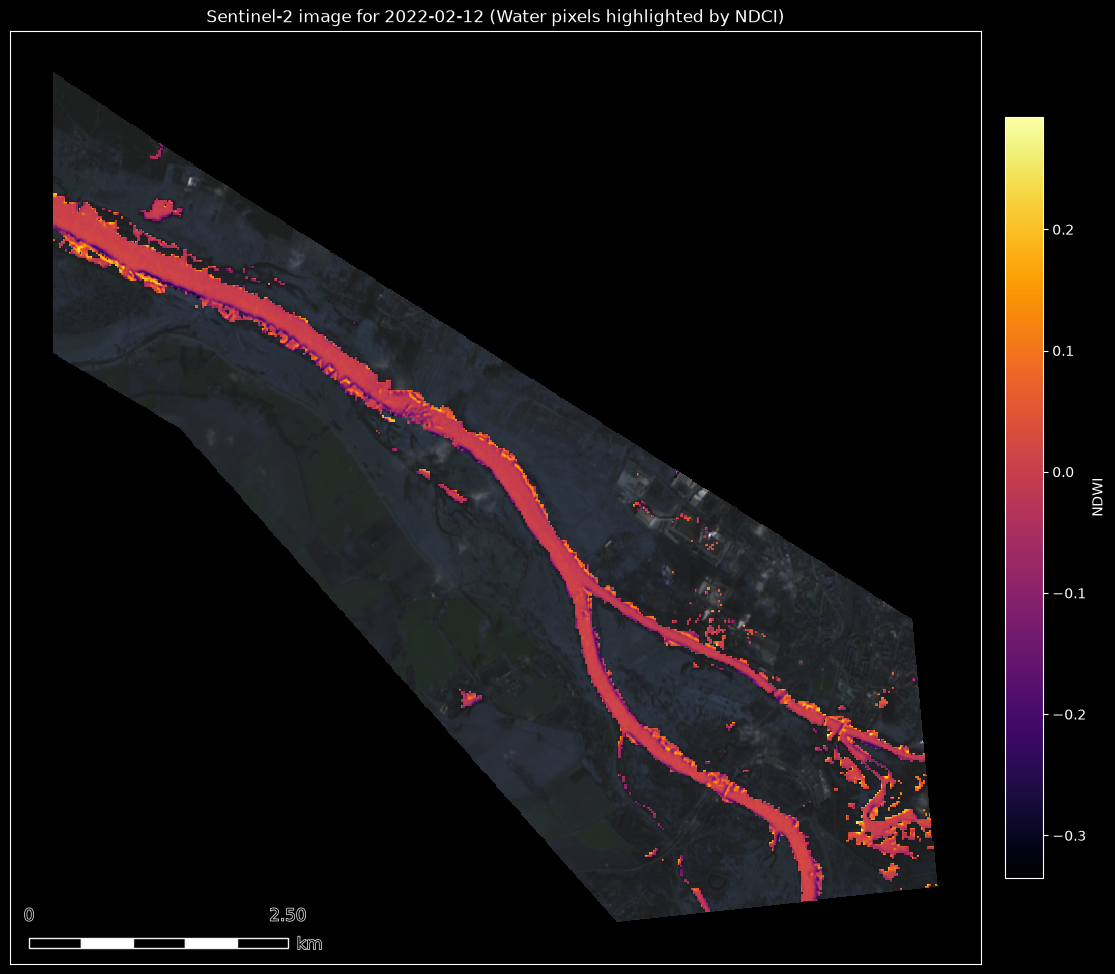

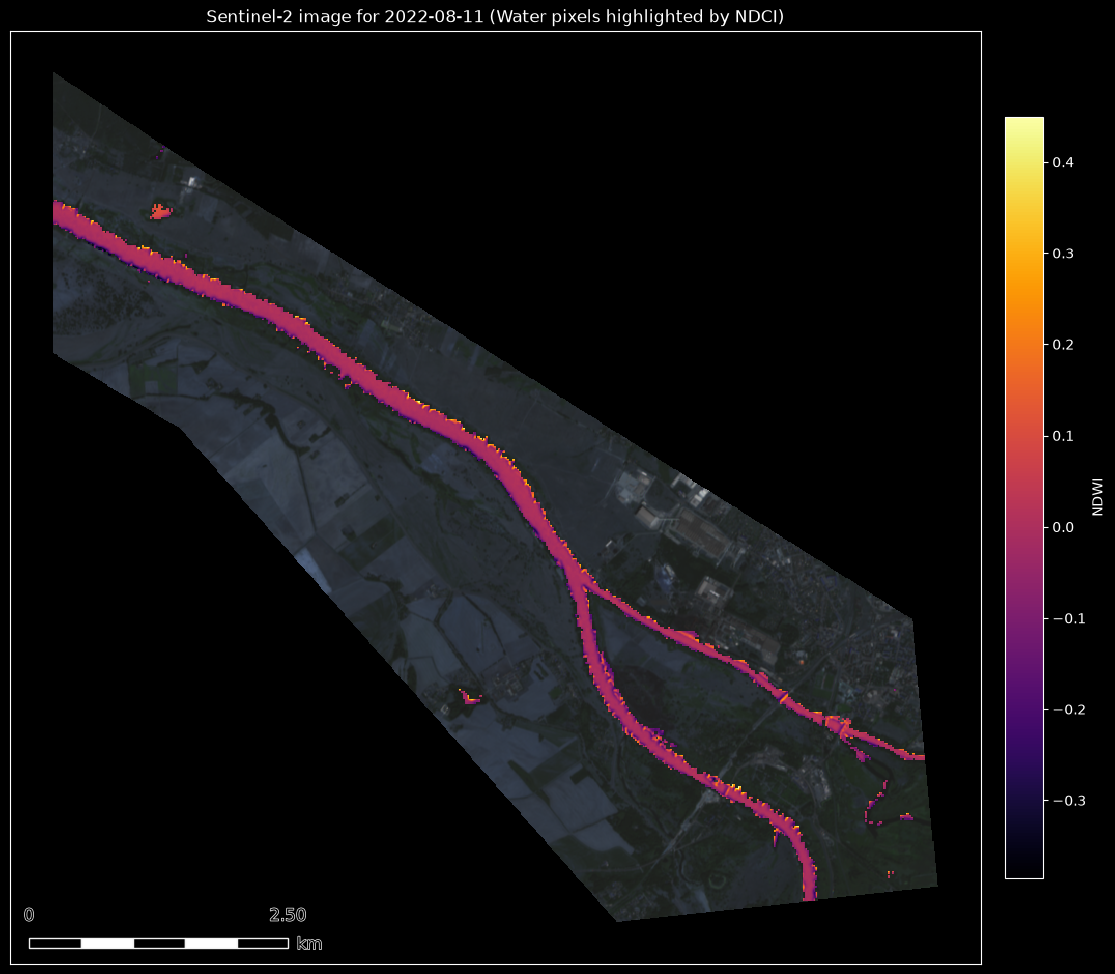

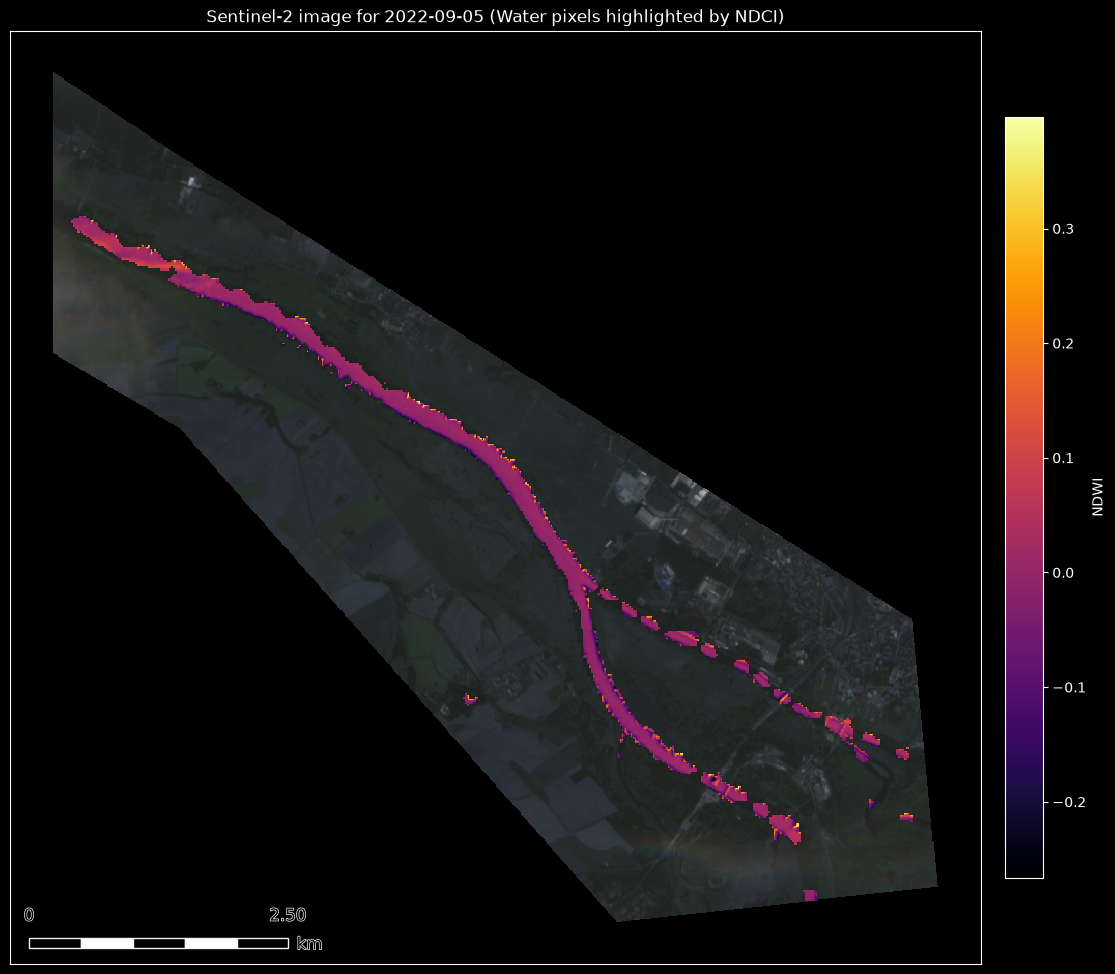

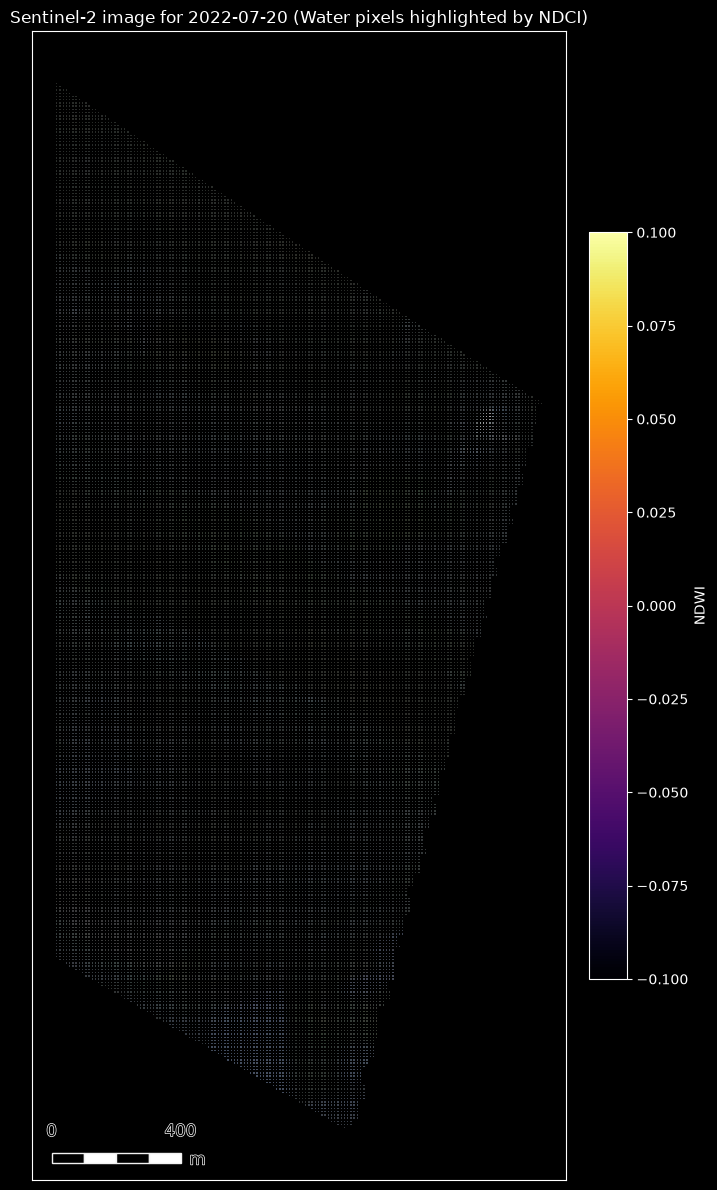

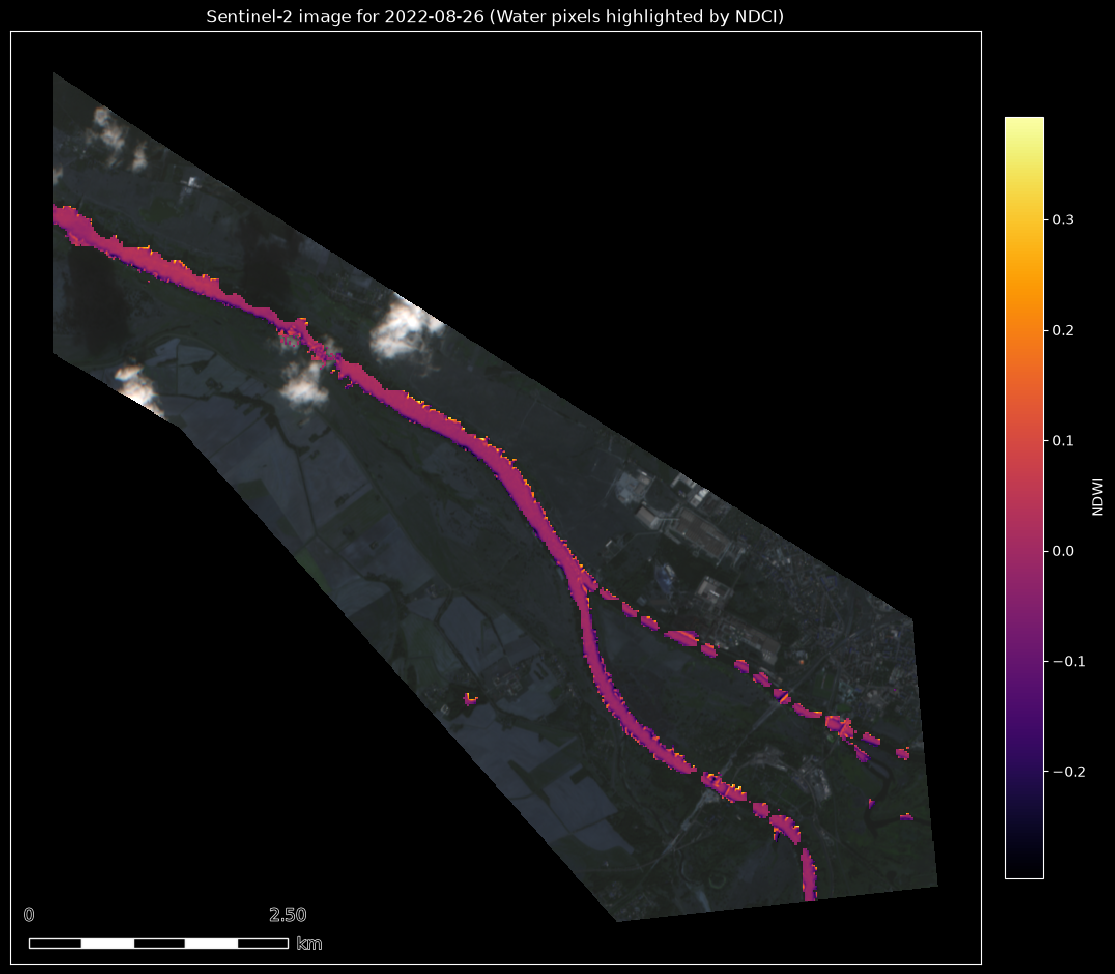

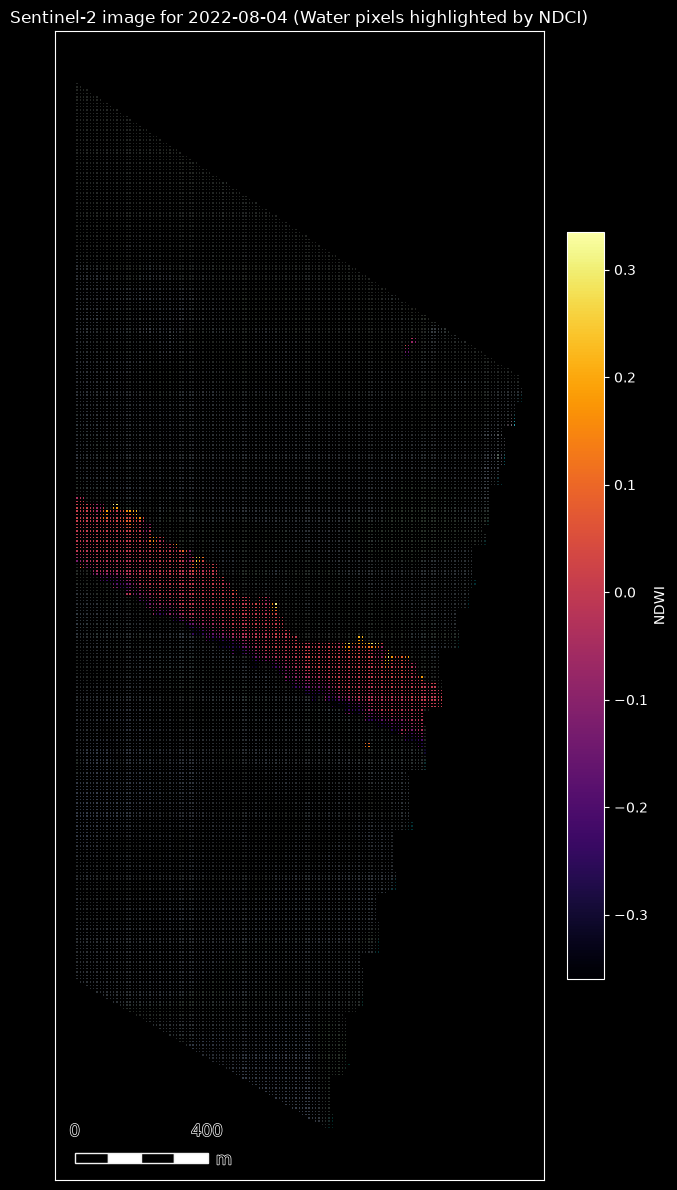

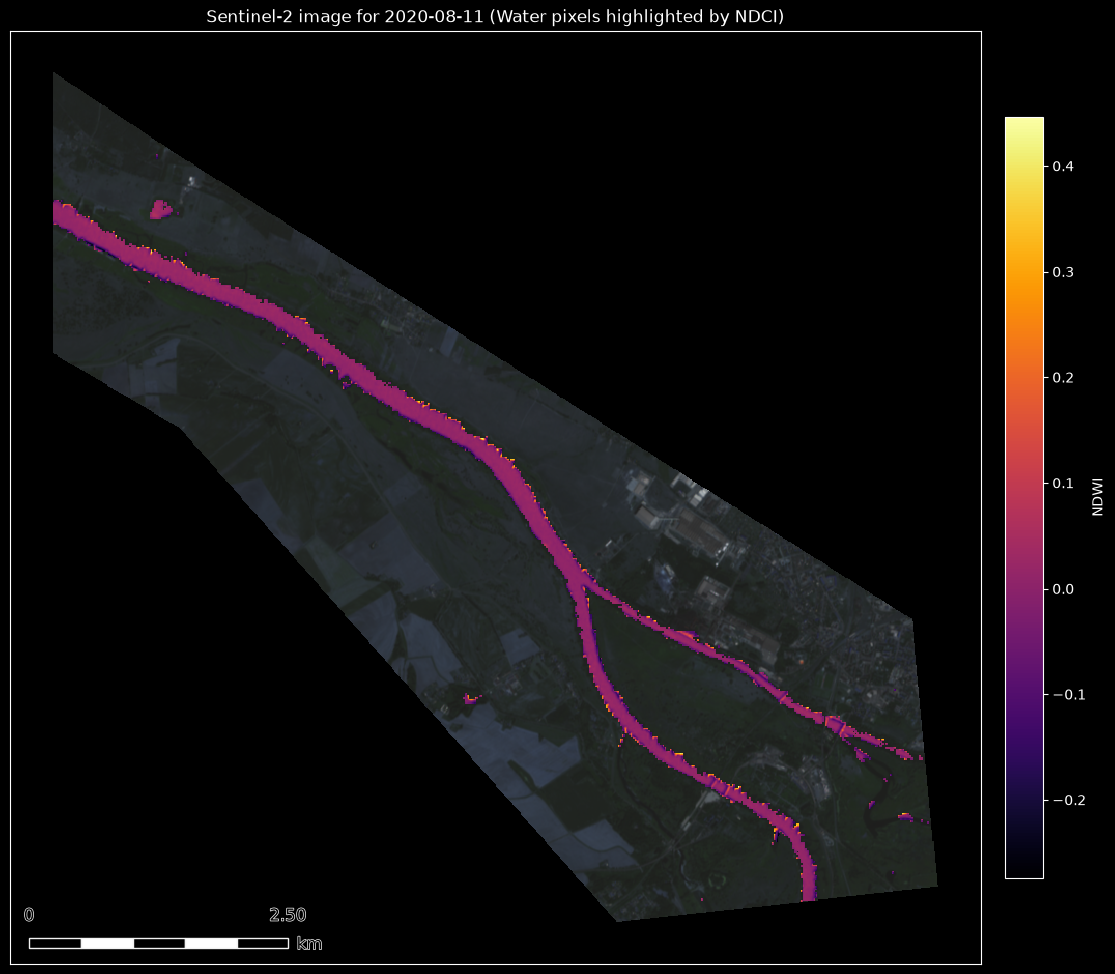

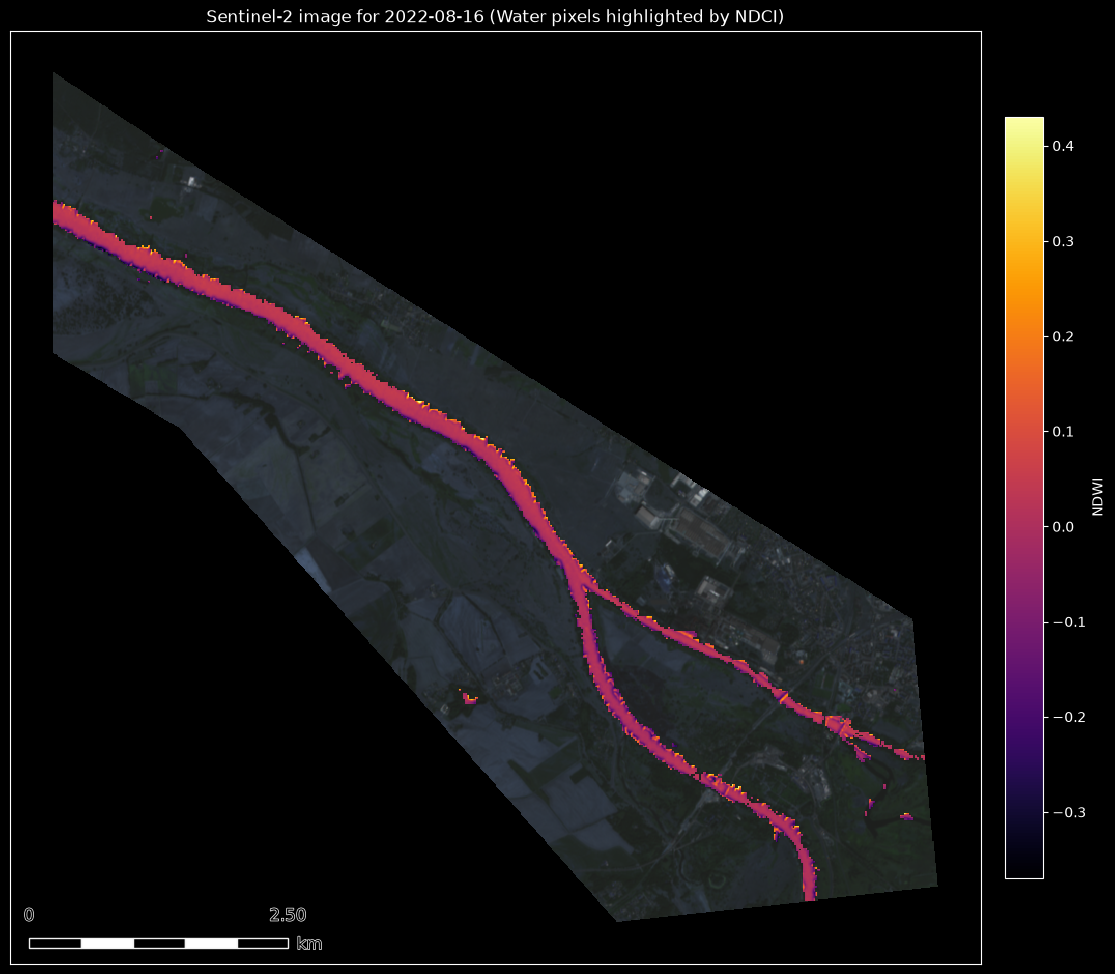

In [ ]:
aoi = "Oder_3"
north, south, east, west = 52.65, 52.57, 14.68, 14.54

for date in date_tiles[:1]:
    year, month, day = date[:4], date[4:6], date[6:8]
    if not aoi in date_tiles[date]:
        continue
    tile = date_tiles[date][aoi]
    df, target_crs = stacks_to_dataframe(
        bands_10m={"B02": 1, "B03": 2, "B04": 3, "B08": 4},
        bands_20m={"B05": 1, "B06": 2, "B07": 3, "B8A": 4, "B11": 5, "B12": 6, "SCL": 7},
        stack_20m_path=tile / "20m_Stack.tif",
        stack_10m_path=tile / "10m_Stack.tif",
    )
    rgb = np.dstack([df["B02"], df["B03"], df["B04"]])

    transformer = Transformer.from_crs(
        "EPSG:4326",
        target_crs,
        always_xy=True,
    )

    corners_lon = [west, west, east, east]
    corners_lat = [south, north, south, north]
    corners_x, corners_y = transformer.transform(
        corners_lon,
        corners_lat,
    )
    x_min, x_max = min(corners_x), max(corners_x)
    y_min, y_max = min(corners_y), max(corners_y)

    plot_df = df[
        (df["x"] >= x_min)
        & (df["x"] <= x_max)
        & (df["y"] >= y_min)
        & (df["y"] <= y_max)
    ].copy()

    rgb = plot_df[["B02", "B03", "B04"]].to_numpy(copy=True)

    water_mask = plot_df["SCL"].eq(6).fillna(False).to_numpy()
    ndwi = (plot_df["B08"] - plot_df["B11"]) / (plot_df["B08"] + plot_df["B11"])
    ndwi[~water_mask] = np.nan
    ndwi_min, ndwi_max = -1, 1
    ndwi[ndwi < ndwi_min] = -1
    ndwi[ndwi > ndwi_max] = ndwi_max

    rgb[rgb > 1.0] = 1.0
    rgb[rgb < 0.0] = 0.0

    fig, ax = plt.subplots(figsize=(12, 12))
    ax.scatter(
        plot_df["x"],
        plot_df["y"],
        c=rgb,
        s=1,
        marker="s",
        linewidths=0,
    )

    cmap = plt.colormaps["inferno"]
    norm = Normalize(vmin=-1.0, vmax=1.0)
    ndwi_sc = ax.scatter(
        plot_df["x"],
        plot_df["y"],
        c=ndwi,
        cmap=cmap,
        s=1,
        marker="s",
        linewidths=0,
    )

    cbar = fig.colorbar(ndwi_sc, ax=ax, pad=0.02, shrink=0.65)
    cbar.set_label("NDWI")


    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Sentinel-2 image for {year}-{month}-{day} (Water pixels highlighted by NDCI)")
    scale_bar(
        ax=ax,
        location="lower left",
        style="boxes",
        bar={"projection":target_crs[-4:],"minor_type":"none","edgecolors": "#f2f2f2"},
        text={"color": "white"},
        labels={"style":"first_last"}
    )

    plt.tight_layout()
    plt.show()


In [4]:
# aoi = "Oder_3"
# north, south, east, west = 52.65, 52.57, 14.68, 14.54

# for date in date_tiles:
#     year, month, day = date[:4], date[4:6], date[6:8]
#     if not aoi in date_tiles[date]:
#         continue
#     tile = date_tiles[date][aoi]
#     df, target_crs = stacks_to_dataframe(
#         bands_10m={"B02": 1, "B03": 2, "B04": 3, "B08": 4},
#         bands_20m={"B05": 1, "B06": 2, "B07": 3, "B8A": 4, "B11": 5, "B12": 6, "SCL": 7},
#         stack_20m_path=tile / "20m_Stack.tif",
#         stack_10m_path=tile / "10m_Stack.tif",
#     )
#     rgb = np.dstack([df["B02"], df["B03"], df["B04"]])

#     transformer = Transformer.from_crs(
#         "EPSG:4326",
#         target_crs,
#         always_xy=True,
#     )

#     corners_lon = [west, west, east, east]
#     corners_lat = [south, north, south, north]
#     corners_x, corners_y = transformer.transform(
#         corners_lon,
#         corners_lat,
#     )
#     x_min, x_max = min(corners_x), max(corners_x)
#     y_min, y_max = min(corners_y), max(corners_y)

#     plot_df = df[
#         (df["x"] >= x_min)
#         & (df["x"] <= x_max)
#         & (df["y"] >= y_min)
#         & (df["y"] <= y_max)
#     ].copy()

#     rgb = plot_df[["B02", "B03", "B04"]].to_numpy(copy=True)

#     water_mask = plot_df["SCL"].eq(6).fillna(False).to_numpy()
#     ndwi = (plot_df["B08"] - plot_df["B11"]) / (plot_df["B08"] + plot_df["B11"])
#     water_mask &= ndwi > 0.0
#     ndci = (plot_df["B05"] - plot_df["B04"]) / (plot_df["B05"] + plot_df["B04"])
#     ndci[~water_mask] = np.nan
#     ndci_min, ndci_max = 0, 0.1
#     ndci[ndci < ndci_min] = ndci_min
#     ndci[ndci > ndci_max] = ndci_max

#     rgb[rgb > 1.0] = 1.0
#     rgb[rgb < 0.0] = 0.0

#     fig, ax = plt.subplots(figsize=(12, 12))
#     ax.scatter(
#         plot_df["x"],
#         plot_df["y"],
#         c=rgb,
#         s=1,
#         marker="s",
#         linewidths=0,
#     )

#     cmap = plt.colormaps["inferno"]
#     norm = Normalize(vmin=0, vmax=0.1)
#     ndci_sc = ax.scatter(
#         plot_df["x"],
#         plot_df["y"],
#         c=ndci,
#         cmap=cmap,
#         s=1,
#         marker="s",
#         linewidths=0,
#     )

#     cbar = fig.colorbar(ndci_sc, ax=ax, pad=0.02, shrink=0.65)
#     cbar.set_label("NDCI")


#     ax.set_aspect("equal")
#     ax.set_xticks([])
#     ax.set_yticks([])
#     ax.set_title(f"Sentinel-2 image for {year}-{month}-{day} (Water pixels highlighted by NDCI)")
#     scale_bar(
#         ax=ax,
#         location="lower left",
#         style="boxes",
#         bar={"projection":target_crs[-4:],"minor_type":"none","edgecolors": "#f2f2f2"},
#         text={"color": "white"},
#         labels={"style":"first_last"}
#     )

#     plt.tight_layout()
#     plt.show()


### Usedom-Wolin archipelago

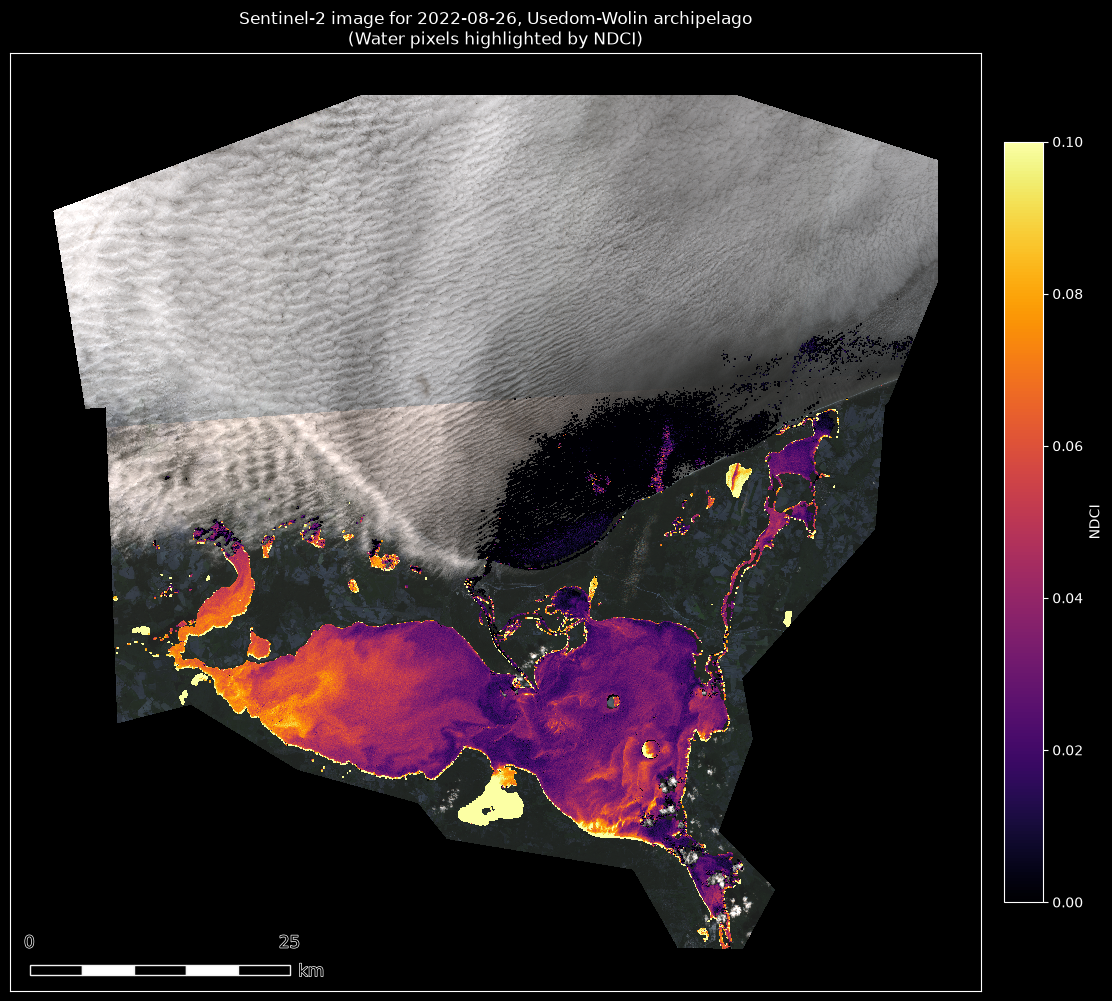

In [7]:
aois = ["Pomeranian_Bay", "Usedom_Wolin", "Szczecin_Lagoon"]
north, south, east, west = 54.3, 53.6, 14.9, 13.59

for date in ["20220826"]:
    year, month, day = date[:4], date[4:6], date[6:8]
    df = None


    for aoi in aois:
        if not aoi in date_tiles[date]:
            continue
        tile = date_tiles[date][aoi]
        local_df, target_crs = stacks_to_dataframe(
            bands_10m={"B02": 1, "B03": 2, "B04": 3, "B08": 4},
            bands_20m={"B05": 1, "B06": 2, "B07": 3, "B8A": 4, "B11": 5, "B12": 6, "SCL": 7},
            stack_20m_path=tile / "20m_Stack.tif",
            stack_10m_path=tile / "10m_Stack.tif",
        )
        transformer = Transformer.from_crs(
            "EPSG:4326",
            target_crs,
            always_xy=True,
        )

        corners_lon = [west, west, east, east]
        corners_lat = [south, north, south, north]
        corners_x, corners_y = transformer.transform(
            corners_lon,
            corners_lat,
        )
        x_min, x_max = min(corners_x), max(corners_x)
        y_min, y_max = min(corners_y), max(corners_y)
        local_df = local_df[
            (local_df["x"] >= x_min)
            & (local_df["x"] <= x_max)
            & (local_df["y"] >= y_min)
            & (local_df["y"] <= y_max)
        ].copy()
        if df is None:
            df = local_df
        else:
            df = pd.concat([df, local_df], ignore_index=True)

    rgb = df[["B02", "B03", "B04"]].to_numpy(copy=True)


    water_mask = df["SCL"].eq(6).fillna(False).to_numpy()
    ndwi = (df["B08"] - df["B11"]) / (df["B08"] + df["B11"])
    water_mask &= ndwi > 0.0
    ndci = (df["B05"] - df["B04"]) / (df["B05"] + df["B04"])
    ndci[~water_mask] = np.nan
    ndci_min, ndci_max = 0, 0.1
    ndci[ndci < ndci_min] = ndci_min
    ndci[ndci > ndci_max] = ndci_max

    rgb[rgb > 1.0] = 1.0
    rgb[rgb < 0.0] = 0.0

    fig, ax = plt.subplots(figsize=(12, 12))
    ax.scatter(
        df["x"],
        df["y"],
        c=rgb,
        s=1,
        marker="s",
        linewidths=0,
    )

    cmap = plt.colormaps["inferno"]
    norm = Normalize(vmin=-1.0, vmax=1.0)
    ndci_sc = ax.scatter(
        df["x"],
        df["y"],
        c=ndci,
        cmap=cmap,
        s=1,
        marker="s",
        linewidths=0,
    )

    cbar = fig.colorbar(ndci_sc, ax=ax, pad=0.02, shrink=0.65)
    cbar.set_label("NDCI")


    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Sentinel-2 image for {year}-{month}-{day}, Usedom-Wolin archipelago\n(Water pixels highlighted by NDCI)")
    scale_bar(
        ax=ax,
        location="lower left",
        style="boxes",
        bar={"projection":target_crs[-4:],"minor_type":"none","edgecolors": "#f2f2f2"},
        text={"color": "white"},
        labels={"style":"first_last"}
    )

    plt.tight_layout()
    plt.show()
